In [1]:
import re
import os
import pandas as pd
import numpy as np
from Bio import SeqIO
from datetime import datetime
from plotnine import ggplot, geom_bar, aes, geom_col, labs, theme, element_blank, element_text

In [2]:
# Goal: see if you can get more fine-scale geographic data for your metadata

In [306]:
# STEP 1: import data

# USDA_DETECTIONS = "./metadata/detections_data/HPAI Detections in Wild Birds (dwnld 2025-01-31).csv"
# CAN_DETECTIONS = "./metadata/detections_data/HPAI_IAHP_Wildlife_Faune__file_fichie.csv"
USDA_DETECTIONS = "./metadata/detections_data/HPAI Detections in Wild Birds (dwld 2025-12-12).csv"
CAN_DETECTIONS = "./metadata/detections_data/HPAI_IAHP_Wildlife_Faune__file_fichie (dwld 2025-12-12).csv"

#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_pb2.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_pb1.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_pa.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_np.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_na.tsv"
#METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_m.tsv"
# METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_ns.tsv"

# METADATA = "./metadata/sequence_metadata/NCBI-BVBRC_FINAL_pb2.tsv"
# METADATA = "./metadata/sequence_metadata/NCBI-BVBRC_FINAL_pb1.tsv"
# METADATA = "./metadata/sequence_metadata/NCBI-BVBRC_FINAL_pa.tsv"
# METADATA = "./metadata/sequence_metadata/NCBI-BVBRC_FINAL_ha.tsv"
# METADATA = "./metadata/sequence_metadata/NCBI-BVBRC_FINAL_np.tsv"
# METADATA = "./metadata/sequence_metadata/NCBI-BVBRC_FINAL_na.tsv"
# METADATA = "./metadata/sequence_metadata/NCBI-BVBRC_FINAL_mp.tsv"
METADATA = "./metadata/sequence_metadata/NCBI-BVBRC_FINAL_ns.tsv"

In [307]:
us_detections = pd.read_csv(USDA_DETECTIONS, sep = ",")
can_detections = pd.read_csv(CAN_DETECTIONS, sep = ",")
#ha_metadata = pd.read_csv(METADATA, sep = "\t")
metadata = pd.read_csv(METADATA, sep = "\t")

In [308]:
metadata.head()
print(metadata.columns)

Index(['Unnamed: 0', 'genbank_acc', 'bp_length', 'ncbibvbrc_segment',
       'ncbibvbrc_nonambigdate', 'ncbibvbrc_date', 'ncbibvbrc_strain',
       'ncbibvbrc_division', 'ncbibvbrc_strain_host', 'ncbibvbrc_order',
       'ncbibvbrc_domesticstatus', 'ncbibvbrc_corrected_host',
       'ncbibvbrc_flyway', 'ncbibvbrc_statecoord', 'ncbibvbrc_hostgroup',
       'ncbibvbrc_country', 'ncbibvbrc_subtype', 'bvbrc_assembled',
       'strain_segment_updated', 'strain', 'year_only', 'month_only', 'source',
       'Genome ID'],
      dtype='object')


In [309]:
# STEP 2: Make any edits to the metadata dataframe

In [310]:
# Subset the metadata to the necessary columns

# needed_columns = ["nonambig_date", "date", "strain_title_updated", "division", "host_fromstrain", "bird_order", "NAflyway", "domesticstatus_combined", 
#                   "year_only", "month_only"]

# ha_metadata_subset = ha_metadata.loc[0:, needed_columns]

In [311]:
# ha_metadata_subset_wild = ha_metadata_subset[ha_metadata_subset["domesticstatus_combined"] == "wild"]

In [312]:
# metadata_wild = metadata[metadata["domesticstatus_combined"] == "wild"]
metadata_wild = metadata[metadata["ncbibvbrc_domesticstatus"] == "wild"]

In [313]:
print(len(metadata))
#print(len(ha_metadata_subset))
#print(len(ha_metadata_subset_wild))
print(len(metadata_wild))

8952
5867


In [314]:
#metadata_hosts = pd.DataFrame(set(ha_metadata_subset_wild["host_fromstrain"]))
#metadata_hosts.to_csv("/Users/claramal/Desktop/metadata_hosts.csv", sep = ',')

In [261]:
# STEP 3: Make any edits to the US detections dataframe

In [262]:
print(len(us_detections))

16651


In [70]:
# Changes that need to be made to the US detections list:
# State: make lowercase, fix for any abbreviations
# County: make lowercase
# Collection Date: fix format to YYYY-MM-DD
# Date Detected: fix format to YYYY-MM-DD
# Bird Species: make lowercase, remove spaces/hyphens/apostrophes
# HPAI Strain: remove anything that isn't EA H5

In [71]:
# State: make lowercase, fix for any abbreviations

us_detections["State"] = us_detections["State"].str.replace(" ","")
us_detections["State"] = us_detections["State"].str.lower()

print(set(us_detections["State"]))

{'ohio', 'indiana', 'maine', 'newjersey', 'northdakota', 'mississippi', 'newmexico', 'kansas', 'northcarolina', 'nevada', 'dc', 'westvirginia', 'louisiana', 'georgia', 'wisconsin', 'colorado', 'utah', 'texas', 'illinois', 'idaho', 'kentucky', 'connecticut', 'massachusetts', 'virginia', 'montana', 'maryland', 'minnesota', 'southcarolina', 'washington', 'nebraska', 'michigan', 'delaware', 'rhodeisland', 'iowa', 'alaska', 'oklahoma', 'oregon', 'florida', 'wyoming', 'newhampshire', 'hawaii', 'california', 'newyork', 'arizona', 'southdakota', 'missouri', 'pennsylvania', 'vermont', 'alabama', 'tennessee', 'arkansas'}


In [72]:
# County: make lowercase, change all spaces/hyphens/dots to underscores

us_detections["County"] = us_detections["County"].str.replace("Parish", "")
us_detections["County"] = us_detections["County"].str.rstrip()
us_detections["County"] = us_detections["County"].str.lstrip()
us_detections["County"] = us_detections["County"].str.replace(".", "")
us_detections["County"] = us_detections["County"].str.replace(" ", "_")
us_detections["County"] = us_detections["County"].str.replace("-", "_")
us_detections["County"] = us_detections["County"].str.replace("'", "")
us_detections["County"] = us_detections["County"].str.lower()

In [73]:
print(set(us_detections["County"]))

{'obion', 'calcasieu', 'fall_river', 'iredell', 'north_slope', 'alcorn', 'craven', 'emmons', 'herkimer', 'mississippi', 'hale', 'columbia', 'perkins', 'richland', 'leflore', 'henry', 'surry', 'district_of_columbia', 'tippecanoe', 'miami_dade', 'butte', 'burnett', 'walker', 'chesterfield', 'posey', 'jackson', 'lowndes', 'prince_william', 'eau_claire', 'charles_city', 'montezuma', 'kalamazoo', 'warren', 'gloucester', 'pocahontas', 'kittson', 'garfield', 'chemung', 'mcpherson', 'alamosa', 'sheboygan', 'canyon', 'gentry', 'desha', 'divide', 'rush', 'oktibbeha', 'poinsett', 'fillmore', 'currituck', 'sarasota', 'lane', 'whitman', 'tama', 'barnstable', 'carson', 'montcalm', 'lamb', 'virginia_beach', 'ford', 'tazewell', 'greenbrier', 'bent', 'chippewa', 'rowan', 'mecosta', 'clarendon', 'gladwin', 'cleveland', 'bollinger', 'forsyth', 'imperial', 'okaloosa', 'merced', 'weld', 'richmond', 'genesee', 'del_norte', 'spink', 'washburn', 'renville', 'davidson', 'coos', 'becker', 'lubbock', 'floyd', 'm

In [74]:
# Make a state_county column

us_detections["state_county"] = us_detections["State"] + '_' + us_detections["County"]

In [75]:
# Some changes have to be made because of incorrect spellings in the detections data

incorrect_statecounty_detectionsdf = {"louisiana_la_salle":"louisiana_lasalle",
                                      "mississippi_de_soto":"mississippi_desoto",
                                      "maryland_st_mary":"maryland_st_marys",
                                      "wisconsin_burnet":"wisconsin_burnett",
                                      "newyork_rensselear":"newyork_rensselaer",
                                      "wisconsin_kewanee":"wisconsin_kewaunee",
                                      "southdakota_stutsman":"northdakota_stutsman",
                                      "southdakota_dickey":"northdakota_dickey",
                                      "virginia_matthews":"virginia_mathews",
                                      "virginia_norfolk_city":"virginia_norfolk",
                                      "kansas_pottawattamie":"kansas_pottawatomie",
                                      "virginia_winchester,_city_of":"virginia_winchester",
                                      "pennsylvania_allegany":"pennsylvania_allegheny",
                                      "indiana_stark":"indiana_starke",
                                      "utah_toole":"utah_tooele"
                                     }

for original_name, corrected_name in incorrect_statecounty_detectionsdf.items():
        us_detections["state_county"] = us_detections["state_county"].replace(original_name, corrected_name)

In [76]:
# Quick check: which Alaskan counties are in the detections data

alaska_detections = us_detections[us_detections["State"] == "alaska"]
print(alaska_detections["County"].value_counts())

# Quick check: which Virginian counties are in the detections data

virginia_detections = us_detections[us_detections["State"] == "virginia"]
print(virginia_detections["County"].value_counts())

County
matanuska_susitna       199
aleutians_east           80
juneau                   36
north_slope              25
sitka                    24
anchorage                24
aleutians_west           20
dillingham               18
bethel                   13
southeast_fairbanks      13
kusilvak                  8
kenai_peninsula           6
fairbanks_north_star      4
yukon_koyukuk             4
nome                      3
haines                    2
ketchikan_gateway         2
valdez_cordova            2
northwest_arctic          1
Name: count, dtype: int64
County
henrico                47
surry                  31
essex                  26
virginia_beach         18
norfolk                17
chesterfield           12
loudoun                 5
waynesboro              5
hampton                 5
fluvanna                4
king_william            3
middlesex               3
northampton             3
orange                  3
suffolk                 3
albemarle               3
tazewell    

In [77]:
# Collection Date: fix format to YYYY-MM-DD
# Date Detected: fix format to YYYY-MM-DD

Collection_Date_unknowns = us_detections["Collection Date"].value_counts().get('Unknown', 0)
print(Collection_Date_unknowns)

Date_Detected_nulls = us_detections["Date Detected"].value_counts().get('null', 0)
print(Date_Detected_nulls)

218
0


In [78]:
# Change the dates in Collection Date (US detections)

us_collect_date_unknowns = []

for index, row in us_detections.iterrows():
    # Ensure the "Collection Date" is not null and is in the expected format
    date_str = row["Collection Date"]
    
    # Check if the date is not null and contains exactly 2 slashes
    if isinstance(date_str, str) and date_str.count("/") == 2:
        # Split the date into month, day, and year
        month, day, year = date_str.split("/")
        
        # Add leading zero to month and day if necessary
        month = month.zfill(2)
        day = day.zfill(2)
        
        # Create the formatted date string in "YYYY-MM-DD" format
        us_detections.at[index, "collect_date"] = f"{year}-{month}-{day}"
    else:
        # Handle invalid date format or missing data (optional)
        # print(f"Skipping invalid date format at index {index}: {date_str}")
        us_collect_date_unknowns.append(index)
        us_detections.at[index, "collect_date"] = None  # Set as None or handle accordingly

In [79]:
# Check to confirm

print(len(us_collect_date_unknowns)) #should be the same number of unknowns...

218


In [80]:
# Change the dates in Date Detected

us_detect_date_unknowns = []

for index, row in us_detections.iterrows():
    # Ensure the "Date Detected" is not null and is in the expected format
    date_str = row["Date Detected"]
    
    # Check if the date is not null and contains exactly 2 slashes
    if isinstance(date_str, str) and date_str.count("/") == 2:
        # Split the date into month, day, and year
        month, day, year = date_str.split("/")
        
        # Add leading zero to month and day if necessary
        month = month.zfill(2)
        day = day.zfill(2)
        
        # Create the formatted date string in "YYYY-MM-DD" format
        us_detections.at[index, "detect_date"] = f"{year}-{month}-{day}"
    else:
        # Handle invalid date format or missing data (optional)
        # print(f"Skipping invalid date format at index {index}: {date_str}")
        us_detect_date_unknowns.append(index)
        us_detections.at[index, "detect_date"] = None  # Set as None or handle accordingly

In [81]:
# Check to confirm

print(len(us_detect_date_unknowns))

0


In [82]:
# Bird Species: make lowercase, remove spaces/hyphens/apostrophes

us_detections_hosts = pd.DataFrame(set(us_detections["Bird Species"]))
print(len(us_detections_hosts))

223


In [83]:
# Print a CSV of the hosts so you can assign synonyms

# total_hosts_2.to_csv("./metadata/helpful_lists/host_synonyms_HPAIdetections.csv", sep = ",")

In [84]:
# Function: drop the hybrid, remove (unidentified), and replace "northenpintail" with "northernpintail"

def alter_us_detections_hosts(df):
    # Loop through DataFrame rows
    df["Bird Species"] = df["Bird Species"].astype(str).str.replace(" ", "", regex=False).str.replace("'", "", regex=False).str.replace("-", "", regex=False).str.lower()
    
    for index, row in df.iterrows():
        host_name = str(row["Bird Species"])

        # First, remove the mallard/blackduckhybrid cause it's weird
        if host_name == "mallard/blackduckhybrid":
            df.drop(index, axis=0, inplace=True)  # Drop row in-place

        # Fix the typo in "northenpintail"
        elif host_name == "northenpintail":  # Correct typo check
            host_name = host_name.replace("northenpintail", "northernpintail")
            df.at[index, "Bird Species"] = host_name  # Update the DataFrame

        # Remove "(unidentified)" from species names
        elif "(unidentified)" in host_name:  # Check if "(unidentified)" is in the name
            host_name = host_name.replace("(unidentified)", "")
            df.at[index, "Bird Species"] = host_name  # Update the DataFrame

        # Remove "(anatidae)" from species names
        elif "(anatidae)" in host_name:  # Check if "(unidentified)" is in the name
            host_name = host_name.replace("(anatidae)", "")
            df.at[index, "Bird Species"] = host_name  # Update the DataFrame

    return df

In [85]:
# Run the above function to fix the bird species names 

us_detections = alter_us_detections_hosts(us_detections)

In [86]:
# Then download the most recent host list, turn it into a dictionary, and use it to assign corrected species names

host_names_df = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ",", encoding='latin-1')

host_names_dict = host_names_df.set_index("strain_host").to_dict(orient="index")

for idx, row in us_detections.iterrows():
    # Check if strain_host exists in the dictionary
    host = row["Bird Species"]
    if host in host_names_dict:
        us_detections.loc[idx, "order"] = host_names_dict[host]["order"]
        us_detections.loc[idx, "domesticstatus"] = host_names_dict[host]["domesticstatus"]
        us_detections.loc[idx, "corrected_host"] = host_names_dict[host]["corrected_host"]
        us_detections.loc[idx, "host_broad"] = host_names_dict[host]["host_group2"]

In [87]:
# HPAI Strain: remove anything that isn't EA H5

print(us_detections["HPAI Strain"].value_counts())

strains_unnecessary = ["EA/AM H5N2", "EA/AM H5N6", "EA H%", "EA/AM H5N6 mixed"]

us_detections_H5N1 = us_detections[~us_detections["HPAI Strain"].isin(strains_unnecessary)]

HPAI Strain
EA/AM H5N1          7576
EA H5N1             5137
EA H5               3674
EA H5N1 mixed         95
EA H5 mixed           72
EA H5N5               30
EA/AM H5              23
EA/AM H5N1 mixed      13
EA/AM H5 mixed         8
EA/AM H5N2             3
EA/AM H5N6             3
EA H5n1                1
EA H%                  1
EA/AM H5N6 mixed       1
EA H5N1 Mixed          1
Name: count, dtype: int64


In [88]:
print(len(us_detections_H5N1))
us_detections_H5N1.head()

16631


,State,County,Collection Date,Date Detected,HPAI Strain,Bird Species,WOAH Classification,Sampling Method,Submitting Agency,state_county,collect_date,detect_date,order,domesticstatus,corrected_host,host_broad
0,florida,st_johns,11/22/2025,12/8/2025,EA H5,greenwingedteal,Wild bird,Hunter harvest,NWDP,florida_st_johns,2025-11-22,2025-12-08,anseriformes,wild,greenwingedteal,duck
1,florida,st_johns,11/22/2025,12/8/2025,EA H5,bluewingedteal,Wild bird,Hunter harvest,NWDP,florida_st_johns,2025-11-22,2025-12-08,anseriformes,wild,bluewingedteal,duck
2,florida,st_johns,11/22/2025,12/8/2025,EA H5,greenwingedteal,Wild bird,Hunter harvest,NWDP,florida_st_johns,2025-11-22,2025-12-08,anseriformes,wild,greenwingedteal,duck
3,florida,st_johns,11/22/2025,12/8/2025,EA H5,greenwingedteal,Wild bird,Hunter harvest,NWDP,florida_st_johns,2025-11-22,2025-12-08,anseriformes,wild,greenwingedteal,duck
4,florida,st_johns,11/22/2025,12/8/2025,EA H5,greenwingedteal,Wild bird,Hunter harvest,NWDP,florida_st_johns,2025-11-22,2025-12-08,anseriformes,wild,greenwingedteal,duck


In [89]:
# STEP 4: Make edits to the Canadian detections datasets

In [90]:
# Changes that need to be made to the Canadian detections list:
# Animal Class: limit to "Avian"
# Province: make lowercase, fix for any abbreviations, change column title to "State"
# CCSNAME: make lowercase, remove symbols, change column title to "county"
# Collection Date: fix format to YYYY-MM-DD
# Result Authorised Date: don't need
# Common Name: make lowercase, remove spaces/hyphens/apostrophes

In [91]:
print(len(can_detections))

3117


In [92]:
# Animal Class: limit to "Avian"

can_detections_aves = can_detections[can_detections["Animal Class"] == "Avian"]

In [93]:
# Province: make lowercase, fix for any abbreviations, change column title to "State"

can_detections_aves_filt = can_detections_aves[can_detections_aves["Province"] != "Atlantic Ocean"]
can_detections_aves_filt["Province"] = can_detections_aves_filt["Province"].str.replace(" ","")
can_detections_aves_filt["Province"] = can_detections_aves_filt["Province"].str.lower()
can_detections_aves_filt = can_detections_aves_filt.rename({"Province":"State"}, axis = 1)

print(set(can_detections_aves_filt["State"]))

{'saskatchewan', 'princeedwardisland', 'newbrunswick', 'ontario', 'alberta', 'novascotia', 'northwestterritories', 'britishcolumbia', 'manitoba', 'newfoundlandandlabrador', 'quebec', 'yukon', 'nunavut'}


/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_46277/30306940.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_46277/30306940.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [94]:
can_county_symbols = {"  ":" ",
                     ". ":"_",
                     ", ":"_",
                     " - ":"_",
                     "--":"_",
                     " / ":"_",
                     "'":"",
                     "(":"",
                     ")":"",
                     "!":"",
                     "&":"and",
                     "é":"e",
                     "è":"e",
                     "ò":"o",
                     "í":"i",
                     "ì":"i",
                     "à":"a",
                     "á":"a",
                     "ú":"u",
                     "ù":"u",
                     "â":"a",
                     "ô":"o",
                     "ê":"e",
                     "ï":"i",
                     "ü":"u",
                     "ë":"e",
                     "ç":"c",
                    }

In [95]:
def replace_symbols(text):
    if isinstance(text, str):
        for symbol, replacement in can_county_symbols.items():
            text = text.replace(symbol, replacement)
    return text

In [96]:
# Function: reorganize can_counties_subset_renamed

def fix_cancounties_dataframe(df):

    df_final = df.copy()

    #Fix the county column
    df_final["County"] = df_final["CCSNAME"]
    df_final["County"] = df_final["County"].str.rstrip()
    df_final["County"] = df_final["County"].str.replace("Î", "i") # have to change this outside of the function, otherwise it won't work
    df_final["County"] = df_final["County"].str.lower()


    df_final["County"] = df_final["County"].apply(replace_symbols)
    
    # Fix these outside of the dictionary because otherwise the apply function will confuse with "  ", " - ", and " / "
    df_final["County"] = df_final["County"].str.replace(" ", "_")
    df_final["County"] = df_final["County"].str.replace("-", "_")
    df_final["County"] = df_final["County"].str.replace("/", "_")

    # If "County" is NaN, put "unknown" in state_county, otherwise put the state and county
    df_final["state_county"] = np.where(df_final["County"].isna(), df_final["State"] + "_unknown", df_final["State"] + "_" + df_final["County"])

    return(df_final)

In [97]:
# Make the final can_counties dataframe

can_detections_aves_filt2 = fix_cancounties_dataframe(can_detections_aves_filt)

In [98]:
print(len(set(can_detections_aves_filt2["state_county"])))

598


In [99]:
# Two incorrect detections in the Canadian dataset
# Coaticook and Compton are in Quebec, not Ontario

can_corrections_dict = {"ontario_coaticook":"quebec_coaticook",
                        "ontario_compton":"quebec_compton"
                       }

for original_name, corrected_name in can_corrections_dict.items():
        can_detections_aves_filt2["state_county"] = can_detections_aves_filt2["state_county"].replace(original_name, corrected_name)

In [100]:
# Collection Date: fix format to YYYY-MM-DD

can_collect_date_unknowns = []

for index, row in can_detections_aves_filt2.iterrows():
    # Ensure the "Collection Date" is not null and is in the expected format
    date_str = row["Collection Date"]
#    print(can_detections_aves_filt2["Collection Date"])
    
    # Check if the date is not null and contains exactly 2 slashes
    if isinstance(date_str, str) and date_str.count(".") == 2:
        # Split the date into month, day, and year
        year = date_str.split(".")[0]
        month = date_str.split(".")[1]
        day = date_str.split(".")[2]
        
        # Add leading zero to month and day if necessary
        month = month.zfill(2)
        day = day.zfill(2)
        
        # Create the formatted date string in "YYYY-MM-DD" format
        can_detections_aves_filt2.at[index, "collect_date"] = f"{year}-{month}-{day}"
    else:
        # Handle invalid date format or missing data (optional)
        print(f"Skipping invalid date format at index {index}: {date_str}")
        can_collect_date_unknowns.append(index)
        can_detections_aves_filt2.at[index, "collect_date"] = None  # Set as None or handle accordingly

In [101]:
# Check to confirm

print(len(can_collect_date_unknowns))

0


In [102]:
# Common Name: make lowercase, remove spaces/hyphens/apostrophes

can_detections_aves_filt3 = can_detections_aves_filt2.copy()

can_detections_aves_filt3["Common Name"] = can_detections_aves_filt3["Common Name"].str.replace(" ", "").str.replace("'", "").str.replace("-", "")
can_detections_aves_filt3["Common Name"] = can_detections_aves_filt3["Common Name"].str.lower()
# Also remove "(duck)", "(gullsandterns)", "(anatidae)"
can_detections_aves_filt3["Common Name"] = can_detections_aves_filt3["Common Name"].str.replace("(duck)", "").str.replace("(gullsandterns)", "").str.replace("(anatidae)", "")

print(len(set(can_detections_aves_filt3["Common Name"])))

canada_detections_hosts = pd.DataFrame(set(can_detections_aves_filt3["Common Name"]))
print(len(canada_detections_hosts))

102
102


In [103]:
# Print a list of all detections hosts

all_detections_hosts = pd.concat([us_detections_hosts, canada_detections_hosts], axis = 0)
all_detections_hosts_deduped = all_detections_hosts.drop_duplicates(subset = 0, keep = "first")
print(len(all_detections_hosts_deduped))

#all_detections_hosts_deduped.to_csv("./metadata/detections_data/detections_hosts.csv", sep = ',')

238


In [104]:
# Then download the most recent host list, turn it into a dictionary, and use it to assign corrected species names

for idx, row in can_detections_aves_filt3.iterrows():
    # Check if strain_host exists in the dictionary
    host = row["Common Name"]
    if host in host_names_dict:
        can_detections_aves_filt3.loc[idx, "order"] = host_names_dict[host]["order"]
        can_detections_aves_filt3.loc[idx, "domesticstatus"] = host_names_dict[host]["domesticstatus"]
        can_detections_aves_filt3.loc[idx, "corrected_host"] = host_names_dict[host]["corrected_host"]
        can_detections_aves_filt3.loc[idx, "host_broad"] = host_names_dict[host]["host_group2"]

In [105]:
# STEP 5: add county-level coordinates to the detections datasets

In [108]:
# Make dictionary of county coordinates

NAm_counties = pd.read_csv("./metadata/helpful_lists/NAm_counties.tsv", sep = "\t")

NAm_counties_dict = NAm_counties.set_index("state_county").to_dict(orient="index")

In [109]:
# Add the centroid of each county to the US detections dataframe in the county_centroid column

us_detections_final_coords = us_detections_H5N1.copy()

missing = []

for idx, row in us_detections_final_coords.iterrows():
    # Check if 'state_county' exists in the dictionary
    state_county = row["state_county"]
    if state_county in NAm_counties_dict:
        # Assign the lat_long value from us_counties_dict to 'county_centroid'
        us_detections_final_coords.loc[idx, "county_centroid"] = NAm_counties_dict[state_county]["lat_long"]
    else:
        missing.append(state_county)

print(set(missing))

{'virginia_hampton', 'virginia_waynesboro', 'virginia_winchester', 'alaska_valdez_cordova', 'indiana_campbell', 'virginia_virginia_beach', 'nebraska_hale', 'virginia_newport_news', 'idaho_stark', 'virginia_portsmouth', 'virginia_norfolk', 'virginia_chesapeake', 'minnesota_dickinson', 'virginia_suffolk'}


In [110]:
# Add the centroid of each county to the Canadian detections dataframe in the county_centroid column

can_detections_final_coords = can_detections_aves_filt3.copy()

for idx, row in can_detections_final_coords.iterrows():
    # Check if 'state_county' exists in the dictionary
    state_county = row["state_county"]
    if state_county in NAm_counties_dict:
        # Assign the lat_long value from us_counties_dict to 'county_centroid'
        can_detections_final_coords.loc[idx, "county_centroid"] = NAm_counties_dict[state_county]["lat_long"]
    else: 
        print(f"missing {state_county} in dictionary")

can_detections_final_coords["city_centroid"] = "unknown"

missing alberta_unknown in dictionary
missing alberta_unknown in dictionary
missing manitoba_unknown in dictionary
missing manitoba_unknown in dictionary
missing manitoba_unknown in dictionary


In [111]:
# For ease, change any NaN in the county_centroid column of the US detections dataset to "unknown"

us_detections_final_coords.loc[us_detections_final_coords["county_centroid"].isna(), "county_centroid"] = "unknown"

In [114]:
# Have to manually add in coordinates for Connecticut counties (because the census doesn't recognize those anymore)

remaining_county_assignments = {
                                # I have added all of these tothe TSV, but am leaving this dictonary in case 
                                #"connecticut_new_haven":"41.35, -72.9",
                                #"connecticut_middlesex":"41.44, -72.52",
                                #"connecticut_hartford":"41.81, -72.73",
                                #"connecticut_new_london":"41.47, -72.1",
                                #"connecticut_tolland":"41.85, -72.33",
                                #"connecticut_fairfield":"41.23, -73.37",
                                #"connecticut_windham":"41.83, -71.99",
                                #"connecticut_litchfield":"41.79, -73.24",
                               }

# Some entries in the detections dataset have city designations, even though they are labeled as county
# Partially this is due to the weird situation in Viginia, where there are counties AND independent cities
# We would like whatever is the most fine-scale coordinate, so I will add these to a city_centroid column

remaining_city_assignments = {"texas_shenandoah":"30.179722, -95.455278", # For city designations, used the coordinates of the city as per GeoHack
                              "indiana_bloomington":"39.162222, -86.522222", # For city designations, used the coordinates of the city as per GeoHack
                              "virginia_norfolk":"36.846944, -76.285278", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "virginia_hampton":"37.026389, -76.344444", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "virginia_waynesboro":"39.748889, -77.581389", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "virginia_virginia_beach":"36.85, -75.977778", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "virginia_chesapeake":"36.714167, -76.238333", # For independent cities, used the centroid of the municipality, as given on GeoHack
                              "indiana_campbell":"38.091667, -87.417778",
                              "virginia_suffolk":"36.741111, -76.609722",
                              "virginia_winchester":"39.183333, -78.166667",
                              "virginia_newport_news":"37.070833, -76.484444",
                              "virginia_portsmouth":"36.834444, -76.341667"
                             }

In [115]:
# Add in remaining counties (connecticut) and cities

us_detections_final_coords_updt = us_detections_final_coords.copy()

us_detections_final_coords_updt["city_centroid"] = "unknown"

# Loop over the rows to fill missing lat_long values using the dictionary
for idx, row in us_detections_final_coords_updt.iterrows():
    state_county = row["state_county"]
    # Check if state_county has a corresponding lat_long in the dictionary
    if (row["county_centroid"] == "unknown") and state_county in remaining_county_assignments:
        # Update the lat_long value using the dictionary
        us_detections_final_coords_updt.at[idx, "county_centroid"] = remaining_county_assignments[state_county]
    elif (row["county_centroid"] == "unknown") and state_county in remaining_city_assignments:
        # Update the lat_long value using the dictionary
        us_detections_final_coords_updt.at[idx, "city_centroid"] = remaining_city_assignments[state_county]
    else:
        pass

In [117]:
# This should check for state_county with no county_centroid and no city_centroid

no_us_centroid_updt = us_detections_final_coords_updt[
    (us_detections_final_coords_updt["county_centroid"] == "unknown") & (us_detections_final_coords_updt["city_centroid"] == "unknown")]

no_centroid = pd.concat([no_us_centroid_updt, can_detections_final_coords[can_detections_final_coords["county_centroid"] == "unknown"]], 
                        axis = 0,
                        join = "outer")

print(no_centroid["state_county"].value_counts())

state_county
britishcolumbia_langley           25
ontario_hamilton                  25
manitoba_portage_la_prairie       19
princeedwardisland_souris         18
alberta_taber                      8
novascotia_lunenburg               6
newbrunswick_gagetown              4
princeedwardisland_tignish         4
newbrunswick_sussex                4
newbrunswick_moncton               3
newbrunswick_caraquet              3
manitoba_morris                    3
princeedwardisland_miscouche       2
newbrunswick_chipman               2
novascotia_yarmouth                2
novascotia_digby                   2
alaska_valdez_cordova              2
newbrunswick_shippagan             2
princeedwardisland_wellington      1
newbrunswick_sackville             1
princeedwardisland_kinkora         1
manitoba_ste_anne                  1
novascotia_shelburne               1
quebec_lange_gardien               1
nebraska_hale                      1
manitoba_dauphin                   1
minnesota_dickinson      

In [118]:
# Concatenate the two detections lists

full_NAm_detections = pd.concat([us_detections_final_coords_updt, can_detections_final_coords], axis = 0, join = "outer")

print(len(full_NAm_detections))

19557


In [119]:
# Are any state_county rows NaN
print(full_NAm_detections["state_county"].isna().value_counts())

# Are any State rows NaN
print(full_NAm_detections["State"].isna().value_counts())

# Are any collect_date rows NaN
print(full_NAm_detections["collect_date"].isna().value_counts())

# Are any corrected_host rows NaN
print(full_NAm_detections["corrected_host"].isna().value_counts())
#print(full_NAm_detections[full_NAm_detections["corrected_host"].isna()])

# Are any county_centroid rows NaN
print(full_NAm_detections["county_centroid"].isna().value_counts())
#print(full_NAm_detections[full_NAm_detections["county_centroid"].isna()])

# Are any city_centroid rows NaN
print(full_NAm_detections["city_centroid"].isna().value_counts())

state_county
False    19557
Name: count, dtype: int64
State
False    19557
Name: count, dtype: int64
collect_date
False    19339
True       218
Name: count, dtype: int64
corrected_host
False    19534
True        23
Name: count, dtype: int64
county_centroid
False    19552
True         5
Name: count, dtype: int64
city_centroid
False    19557
Name: count, dtype: int64


In [315]:
# STEP 6: add coordinates to sequencing data via detections data

In [316]:
# Comparison: if species, state, AND date detected matches, then add county to metadata in that row

In [317]:
# Loop: Attempt 1

# for row in ha_metadata_subset:
#     if row["date"] in detections_H5N1_newcolumns["date"].at(idx):
#         try:
#             if row["division"] in detections_H5N1_newcolumns["division"].at(idx):
#                 finally:
#                     if row["host_fromstrain"] in detections_H5N1_newcolumns["host_fromstrain"].at(idx):
#                         ha_metadata_subset["county"] = detections_H5N1_newcolumns["County"].at(idx)
#     else:
#         ha_metadata_subset["county"].isna()

In [318]:
# Function: what to do when a matching row(s) exists 
# This function is intended as a nesting function inside the next function

def filling_rows(metadata_finescale, idx, matching_rows):
    
    unique_counties_in_match = set(matching_rows["County"].tolist())
    
    # if matching rows exist, this function will follow a specific set of instructions
    if len(unique_counties_in_match) == 1: 
                # If there is one "county" match and it is actually a county (i.e. middlesex), add the county and county_centroid
                if not matching_rows["county_centroid"].iloc[0] == "unknown":
                    metadata_finescale.at[idx, "county"] = matching_rows["County"].iloc[0]
                    metadata_finescale.at[idx, "city"] = "unknown"
                    metadata_finescale.at[idx, "county_lat-long"] = matching_rows["county_centroid"].iloc[0]
                    metadata_finescale.at[idx, "city_lat-long"] = "unknown"
                # If there is one "county" match but it is actually a city (i.e. virginia_beach), add the city and city_centroid
                elif (matching_rows["county_centroid"].iloc[0] == "unknown") and not (matching_rows["city_centroid"].iloc[0] == "unknown"):
                    metadata_finescale.at[idx, "county"] = "unknown"
                    metadata_finescale.at[idx, "city"] = matching_rows["County"].iloc[0]
                    metadata_finescale.at[idx, "county_lat-long"] = "unknown"
                    metadata_finescale.at[idx, "city_lat-long"] = matching_rows["city_centroid"].iloc[0]
                # If the "county" match is "unknown" and there is no "city" match
                elif (matching_rows["county_centroid"].iloc[0] == "unknown") and (matching_rows["city_centroid"].iloc[0] == "unknown"):
                    metadata_finescale.at[idx, "county"] = "unknown"
                    metadata_finescale.at[idx, "city"] = "unknown"
                    metadata_finescale.at[idx, "county_lat-long"] = "unknown"
                    metadata_finescale.at[idx, "city_lat-long"] = "unknown"
                else:
                    print(f"Unexpected condition at index {idx}")
                    
    # If there is more than one "county" match in matching rows
    elif len(unique_counties_in_match) > 1:
        metadata_finescale.at[idx, "county"] = "unknown"
        metadata_finescale.at[idx, "city"] = "unknown"
        metadata_finescale.at[idx, "county_lat-long"] = "unknown"
        metadata_finescale.at[idx, "city_lat-long"] = "unknown"

    # If no matching rows are found, set county to "unknown"
    else:
        print(f"Unexpected case (no matching counties) at index {idx}")

    return(metadata_finescale)

In [319]:
# Function: how to detect and fill matching rows

def matching_datehostdivision(metadata, detections):

    metadata_finescale = metadata.copy()
    
    for idx, row in metadata_finescale.iterrows():
        # Find rows in detections_H5N1_newcolumns that match the current row's values
        matching_rows = detections[
            (detections["collect_date"] == row["ncbibvbrc_date"]) &
            (detections["State"] == row["ncbibvbrc_division"]) &
            (detections["corrected_host"] == row["ncbibvbrc_corrected_host"])
        ]

        # counties in match is just a list of the counties in the matched rows; eg: ["lake","granite"] or ["lake","lake","lake"]
        counties_in_match = matching_rows["County"].tolist()
        # unique counties in match is a set of the counties in matched rows; eg: {"lake","granite"} or {"lake"}
        unique_counties_in_match = set(matching_rows["County"].tolist())

        
        # If matching rows exist, assign the corresponding county or value
        if not matching_rows.empty:
            metadata_finescale = filling_rows(metadata_finescale, idx, matching_rows)
        else: 
            metadata_finescale.at[idx, "county"] = "unknown" 
            metadata_finescale.at[idx, "county_lat-long"] = "unknown" 
            metadata_finescale.at[idx, "city"] = "unknown" 
            metadata_finescale.at[idx, "city_lat-long"] = "unknown"

    return(metadata_finescale)

In [320]:
metadata_NAm_county = matching_datehostdivision(metadata_wild, full_NAm_detections)

In [321]:
# Check for length (did this process delete any rows)

print(len(metadata_wild))
print(len(metadata_NAm_county))

5867
5867


In [322]:
# Check for duplicates (did this process duplicate any rows)

print(metadata_NAm_county["strain_segment_updated"].is_unique)

True


In [323]:
# What percentage of rows have an entry in the county column

print(metadata_NAm_county["county"].value_counts())

# What percentage of rows have an entry in the city column 

print(metadata_NAm_county["city"].value_counts())

county
unknown                          2163
brevard                            91
barnstable                         64
essex                              52
aleutians_east                     50
                                 ... 
cariboo_i                           1
saint_polycarpe                     1
north_dundas                        1
greater_sudbury_grand_sudbury       1
racine                              1
Name: count, Length: 910, dtype: int64
city
unknown           5849
norfolk             12
hampton              4
virginia_beach       2
Name: count, dtype: int64


In [324]:
# Heres the situation: 
# Point 1: detections for both Canada and the US are for wildlife, and don't include domestic detections
# Point 2: there are some sequences from Newfoundland in mid-December 2021 (the start of the outbreak) in domestic birds
# So, I want to add in those four sequences to this metadata with county detections

print(metadata_NAm_county["strain"].loc[metadata["year_only"] == 2021]) # some are in there

metadata_2021_nl = metadata[(metadata["year_only"] == 2021) & (metadata["ncbibvbrc_division"] == "newfoundland")]
# print(metadata_2021_nl["strain"].to_list())

# Only add a few of the domestic strains in
to_add = ['a/fancychicken/nl/fav003312021/2021|2021-11-15|domestic|galliformes|AtlanticFlyway',
         'a/domesticbird/nl/fav003552021/2021|2021-12-16|domestic|other|AtlanticFlyway',
         'a/domesticbird/nl/fav000442022/2021|2021-12-31|domestic|other|AtlanticFlyway'
         ]
metadata_to_add = metadata.loc[metadata["strain"].isin(to_add)]
# print(len(metadata_to_add))

# Add some to metadata_NAm_county
metadata_NAm_county_withadditions = pd.concat([metadata_NAm_county, metadata_to_add], axis = 0, join = "outer")
print(len(metadata_NAm_county_withadditions))

# Create a boolean mask for rows in metadata_NAm_county where strain is in metadata_firstfour["strain"]
mask = metadata_NAm_county_withadditions["strain"].isin(metadata_to_add["strain"])

# Set the columns to "unknown" where mask is True
metadata_NAm_county_withadditions.loc[mask, ["county", "county_lat-long", "city", "city_lat-long"]] = "unknown"

11      a/americanblackduck/nl/oth0004142021/2021|2021...
12      a/americanblackduck/nl/oth0004162021/2021|2021...
454     a/americanwigeon/southcarolina/22000345001/202...
457     a/americanwigeon/southcarolina/ah0195145/2021|...
1525    a/bluewingedteal/southcarolina/22000345003/202...
5082    a/greatblackbackedgull/nl/oth011412021/2021|20...
Name: strain, dtype: object
5870


In [325]:
metadata_NAm_county_withadditions.head()

,Unnamed: 0,genbank_acc,bp_length,ncbibvbrc_segment,ncbibvbrc_nonambigdate,ncbibvbrc_date,ncbibvbrc_strain,ncbibvbrc_division,ncbibvbrc_strain_host,ncbibvbrc_order,...,strain_segment_updated,strain,year_only,month_only,source,Genome ID,county,city,county_lat-long,city_lat-long
0,7,OQ957616.1,838.0,8.0,2022-02-06,2022-02-06,a/americanblackduck/connecticut/22005000001/2022,connecticut,americanblackduck,anseriformes,...,a/americanblackduck/connecticut/22005000001/20...,a/americanblackduck/connecticut/22005000001/20...,2022,2,ncbibvbrc,11320.455523,new_london,unknown,"41.47, -72.1",unknown
1,15,OQ957624.1,838.0,8.0,2022-02-16,2022-02-16,a/americanblackduck/connecticut/22005313006/2022,connecticut,americanblackduck,anseriformes,...,a/americanblackduck/connecticut/22005313006/20...,a/americanblackduck/connecticut/22005313006/20...,2022,2,ncbibvbrc,11320.455530,new_haven,unknown,"41.35, -72.9",unknown
2,23,OQ957632.1,838.0,8.0,2022-02-16,2022-02-16,a/americanblackduck/connecticut/22005313007/2022,connecticut,americanblackduck,anseriformes,...,a/americanblackduck/connecticut/22005313007/20...,a/americanblackduck/connecticut/22005313007/20...,2022,2,ncbibvbrc,11320.455539,new_haven,unknown,"41.35, -72.9",unknown
3,31,OQ957640.1,838.0,8.0,2022-02-16,2022-02-16,a/americanblackduck/connecticut/22005313008/2022,connecticut,americanblackduck,anseriformes,...,a/americanblackduck/connecticut/22005313008/20...,a/americanblackduck/connecticut/22005313008/20...,2022,2,ncbibvbrc,11320.455547,new_haven,unknown,"41.35, -72.9",unknown
4,39,PQ701325.1,838.0,8.0,2022-10-31,2022-10-31,a/americanblackduck/ma/23001397010original/2022,massachusetts,americanblackduck,anseriformes,...,a/americanblackduck/massachusetts/23001397010/...,a/americanblackduck/ma/23001397010original/202...,2022,10,ncbibvbrc,11320.718248,barnstable,unknown,"41.706123, -70.164823",unknown


In [326]:
# This was a useful function (so I am keeping it somewhere) but it is DEPRECATED (so I am keeping it buried)
# Function: Assign a column that indicates which lat_long to use

# def assign_lat_long(row):

#     # If both city_lat-long and county_lat-long are "unknown", use state_coord
#     if row["city"] == "unknown" and row["county"] == "unknown":
#         return row["state_coord"]
        
#     # If city_lat-long is "unknown", but county_lat-long is not, use county_lat-long
#     elif row["city"] == "unknown" and row["county"] != "unknown":
#         return row["county_lat-long"]
        
#     # If county_lat-long is "unknown", but city_lat-long is not, use city_lat-long
#     elif row["county"] == "unknown" and row["city"] != "unknown":
#         return row["city_lat-long"]
        
#     # If neither condition is met, return None or some other default value
#     else:
#         print(f"Something unexpected at index {row.name}")
#         return None  # You can return a specific value if needed

In [327]:
def assign_lat_long(df):
    # Initialize the new columns with default values (optional)
    df['lat_long_to_use'] = None
    df['lat_long_source'] = None

    # Apply the logic using vectorized conditions
    df.loc[(df['city'] == 'unknown') & (df['county'] == 'unknown'), 'lat_long_to_use'] = df['ncbibvbrc_statecoord']
    df.loc[(df['city'] == 'unknown') & (df['county'] != 'unknown'), 'lat_long_to_use'] = df['county_lat-long']
    df.loc[(df['county'] == 'unknown') & (df['city'] != 'unknown'), 'lat_long_to_use'] = df['city_lat-long']

    # Assign the corresponding source labels
    df.loc[(df['city'] == 'unknown') & (df['county'] == 'unknown'), 'lat_long_source'] = 'state'
    df.loc[(df['city'] == 'unknown') & (df['county'] != 'unknown'), 'lat_long_source'] = 'county'
    df.loc[(df['county'] == 'unknown') & (df['city'] != 'unknown'), 'lat_long_source'] = 'city'

    # Optional: For rows that don't match any condition, you can handle them here
    if df['lat_long_to_use'].isnull().any():
        print(f"Something unexpected at indices: {df[df['lat_long_to_use'].isnull()].index.tolist()}")

    return df

In [328]:
#ha_metadata_wild_completefinescale = assign_lat_long(ha_metadata_full_withcounty)

metadata_wild_completefinescale = assign_lat_long(metadata_NAm_county_withadditions)

In [329]:
print(metadata_wild_completefinescale["lat_long_source"].value_counts())

lat_long_source
county    3704
state     2148
city        18
Name: count, dtype: int64


In [330]:
# Add lat and long columns that take from the value in the lat_long_to_use column

metadata_wild_completefinescale["lat_long_to_use"] = metadata_wild_completefinescale["lat_long_to_use"].str.replace(" ","")

metadata_wild_completefinescale["lat"] = metadata_wild_completefinescale["lat_long_to_use"].str.split(",", expand=True)[0]
metadata_wild_completefinescale["long"] = metadata_wild_completefinescale["lat_long_to_use"].str.split(",", expand=True)[1]

In [331]:
# Print the final data!

#ha_metadata_wild_completefinescale.to_csv("./test4.csv", sep = ",")

# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC_pb2_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC_pb1_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC_pa_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC_ha_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC_np_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC_na_detectionsgeodata.tsv", sep = "\t")
# metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC_mp_detectionsgeodata.tsv", sep = "\t")
metadata_wild_completefinescale.to_csv("./metadata/sequence_metadata/NCBI-BVBRC_ns_detectionsgeodata.tsv", sep = "\t")

In [332]:
metadata_wild_completefinescale = pd.read_csv("./metadata/sequence_metadata/NCBI-BVBRC_ha_detectionsgeodata.tsv", sep = "\t")

In [333]:
def format_date(datestr):
    i = str(datestr)
    date_object = datetime.strptime(i, '%Y-%m-%d')
    return (date_object)

In [337]:
metadata_wild_completefinescale["nonambig_date"] = metadata_wild_completefinescale["ncbibvbrc_nonambigdate"].apply(format_date)

lat_long_source
county    3702
state     2149
city        18
Name: count, dtype: int64


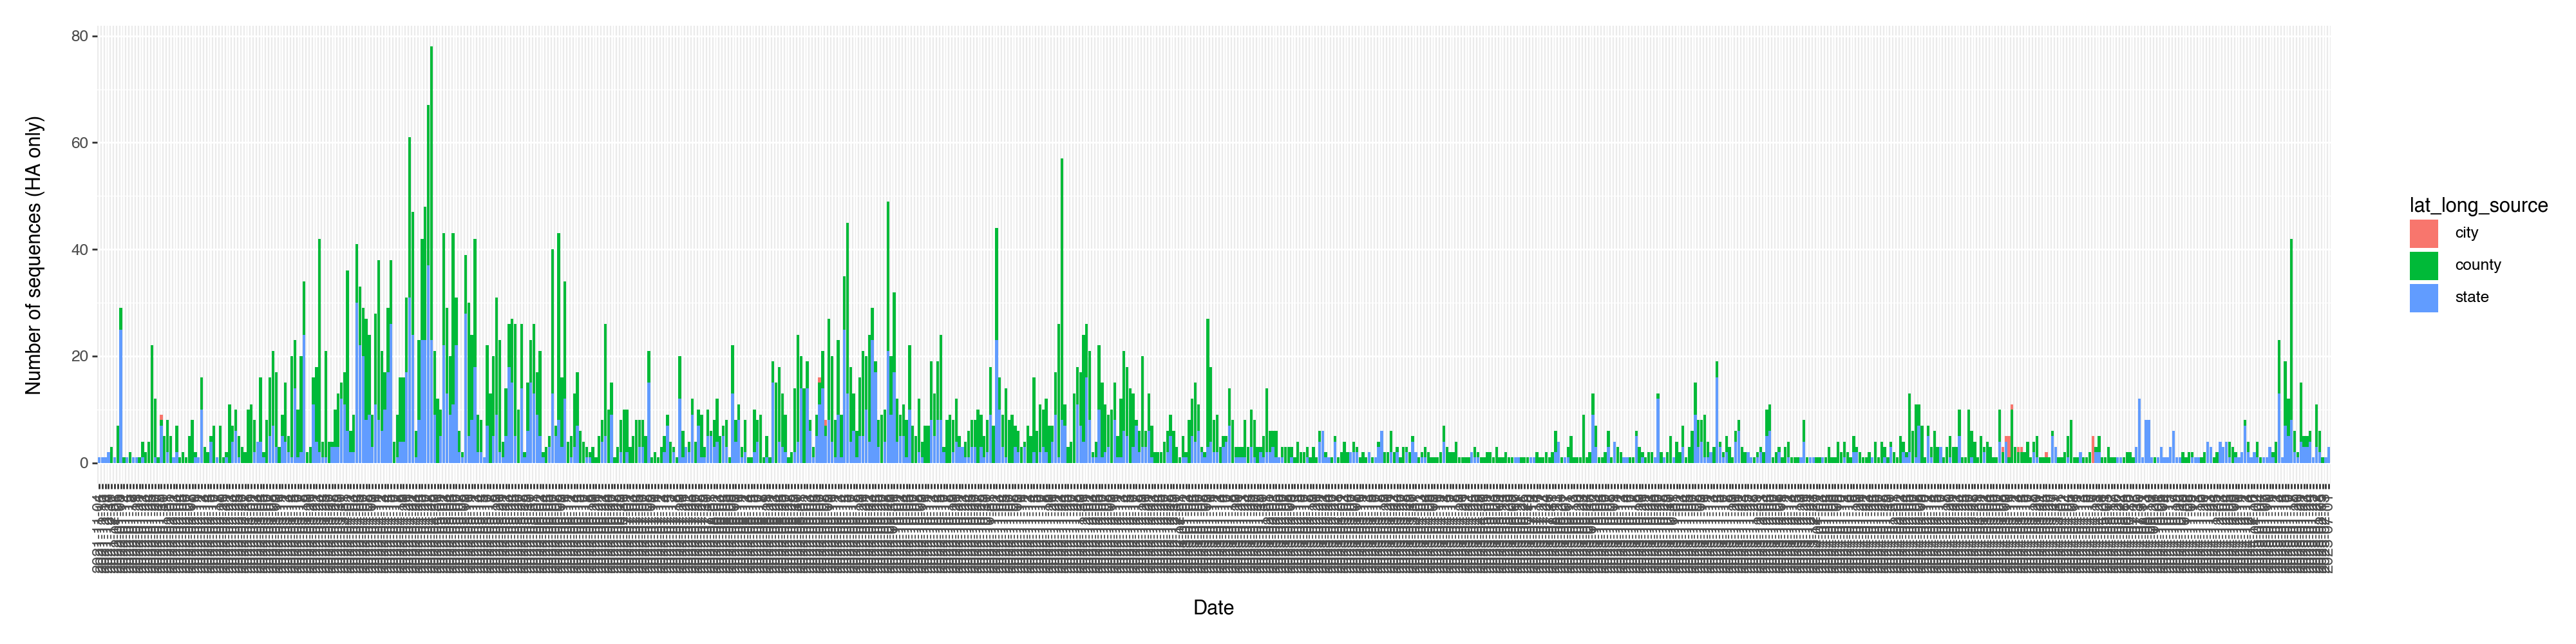

In [338]:
# Plot some of this data!

print(metadata_wild_completefinescale["lat_long_source"].value_counts())

lat_long_source_overtime = (
    ggplot(metadata_wild_completefinescale, aes(x = "ncbibvbrc_nonambigdate", fill = "lat_long_source"))
    + geom_bar(stat = "count")
    + labs(x = "Date", y = "Number of sequences (HA only)")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (20, 5))
)

lat_long_source_overtime.show()

# lat_long_source_overtime.save(filename = './metadata/exploratory_data_analysis/coordinate_source_over_time.png', height=10, width=20, units = 'in', dpi=750)

In [79]:
# Can I figure out the overlap of bird species names?

# First, concatenate the two lists of hosts
total_hosts = pd.concat([metadata_hosts,detections_hosts], axis = 0, join = "outer", ignore_index = True)

total_hosts = total_hosts.rename({0:"hosts"}, axis = 1)

total_hosts.head()

# Next, plot the results
(
    ggplot(total_hosts, aes(x = "hosts"))
    + geom_bar(stat = "count")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (20, 5))
)

# If count = 2, then both metadata and detections have the same name for that host
# If count = 1, there is a missmatch

NameError: name 'metadata_hosts' is not defined

In [477]:
# Another way to visualize the above

# This time, merge the two lists of hosts and add a column for source
total_hosts_2 = metadata_hosts.merge(detections_hosts, on = 0, how = "outer", indicator = True)

total_hosts_2 = total_hosts_2.rename({0:"hosts"}, axis = 1)

mapper = {"right_only":"detection_data","left_only":"metadata","both":"both"}
total_hosts_2["source"] = total_hosts_2["_merge"].map(mapper)

total_hosts_2.head()

# Next, plot the results
(
    ggplot(total_hosts_2, aes(x = "hosts", fill = "source"))
    + geom_bar(stat = "count")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (20, 5))
)

NameError: name 'metadata_hosts' is not defined